/tmp/ipython-input-1273039981.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("NVDA", start="2020-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed

Epoch 1/100



/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - loss: 0.0528 - val_loss: 0.1924
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0048 - val_loss: 0.0483
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 0.0027 - val_loss: 0.0323
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.0024 - val_loss: 0.0176
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - loss: 0.0021 - val_loss: 0.0174
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0023 - val_loss: 0.0114
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0020 - val_loss: 0.0084
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0022 - val_loss: 0.0094
Epoch 9/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 0.0019 - val_loss: 0.0062
Epoch 10/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.0019 - val_loss: 0.0043
Epoch 11/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 0.0018 - val_loss: 0.0080
Epoch 12/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0

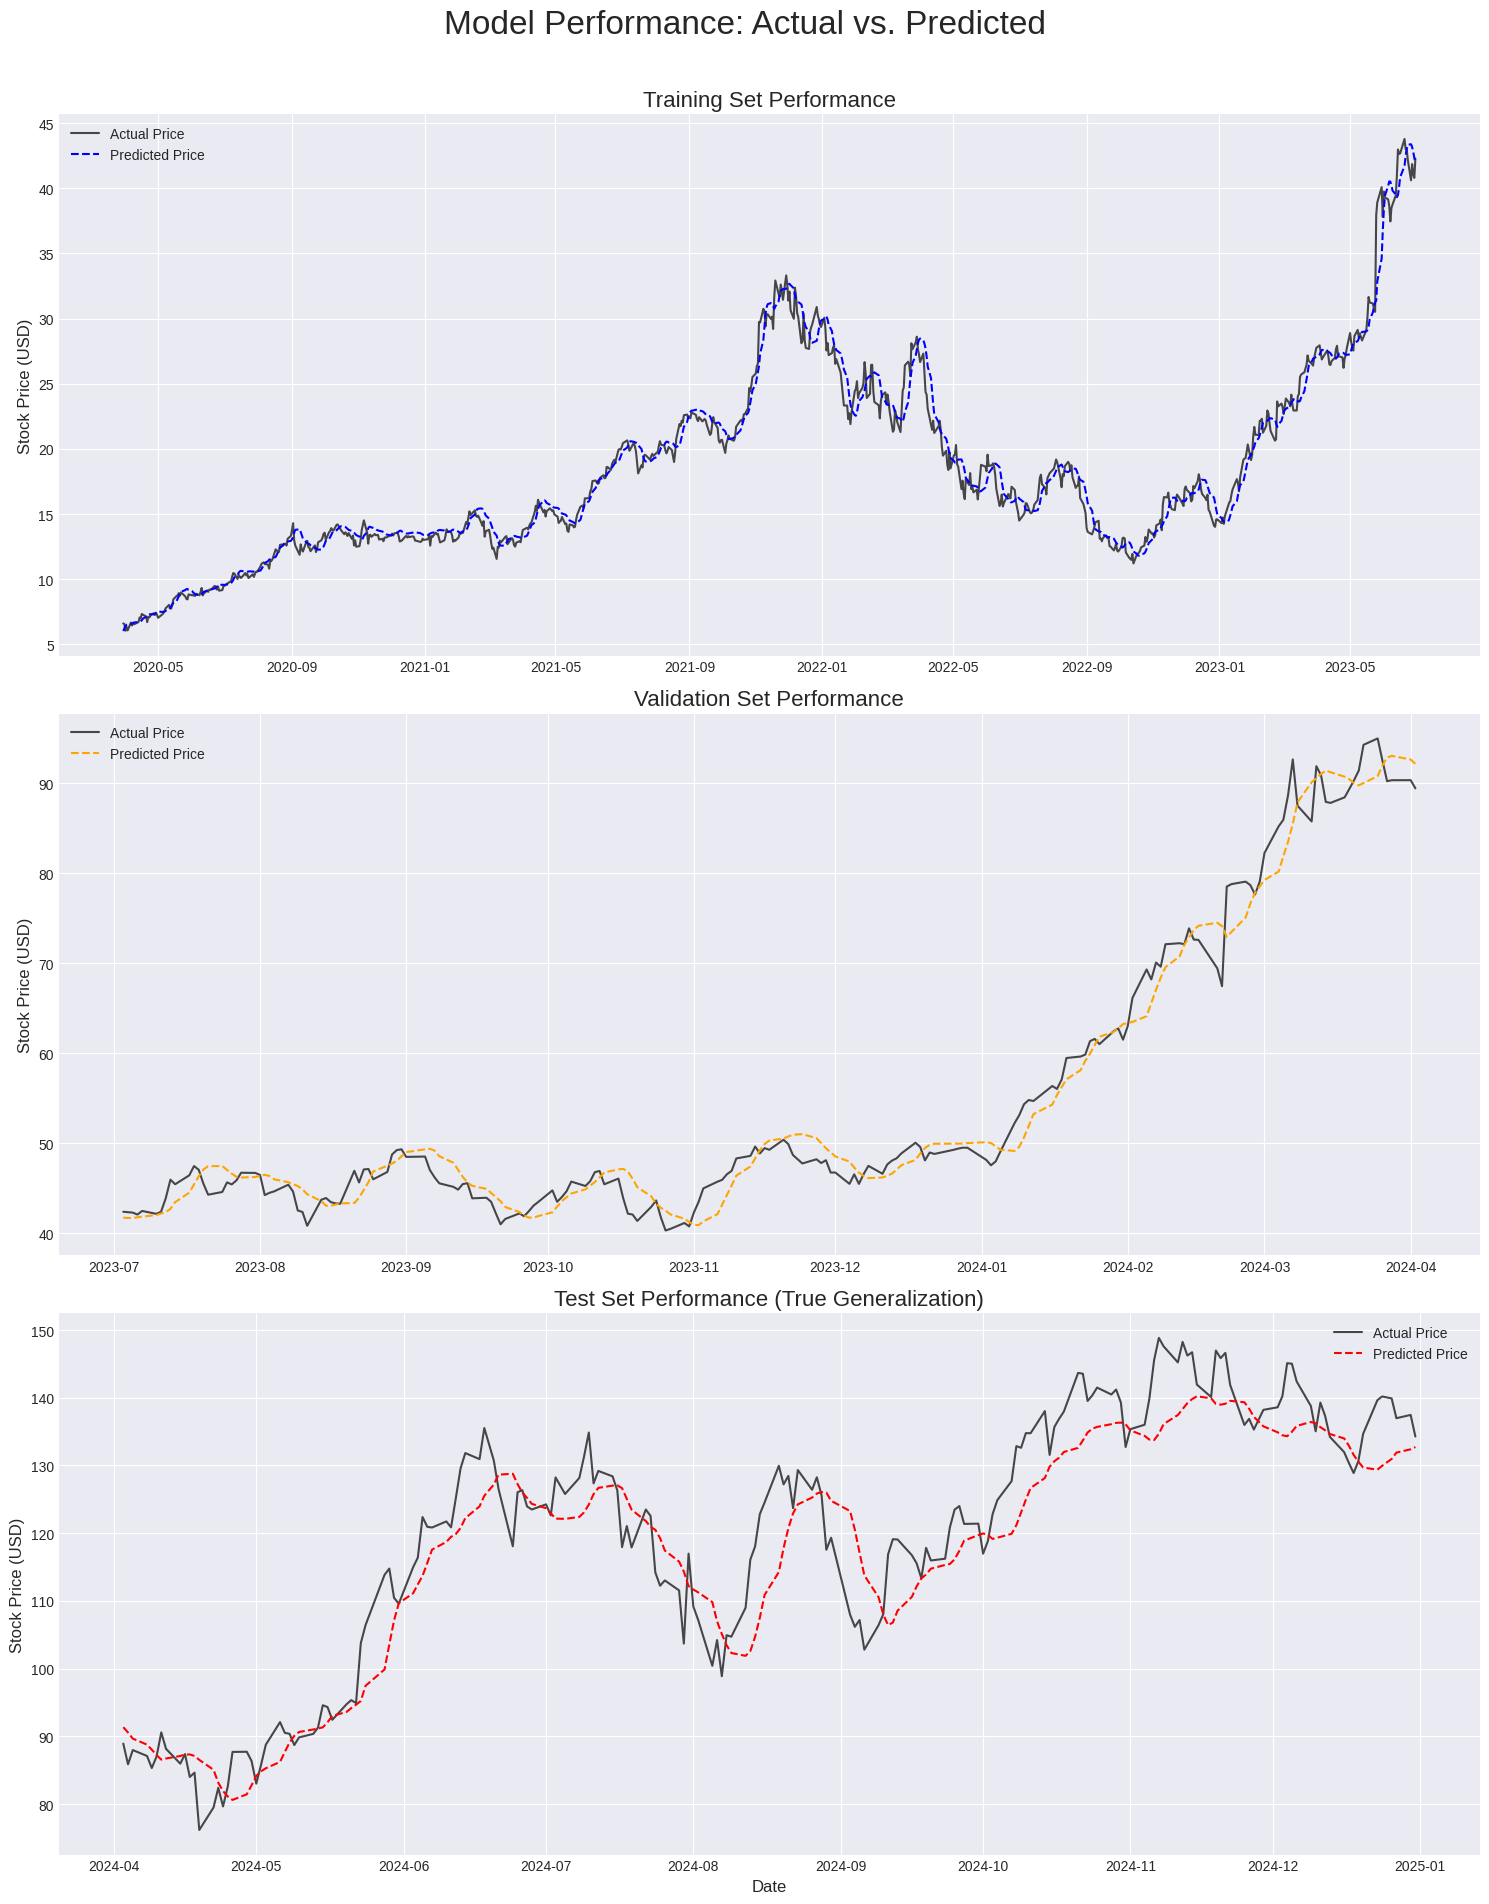

In [9]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Download NVIDIA data
df = yf.download("NVDA", start="2020-01-01", end="2025-01-01")

# --- 1. Data Preparation for Regression ---
features = ['Open', 'High', 'Low', 'Close', 'Volume']
data = df[features]
close_feature_index = features.index('Close')

# Split data (70-15-15)
train_size = int(len(data) * 0.70)
val_size = int(len(data) * 0.85)
train_data = data[:train_size]
val_data = data[train_size:val_size]
test_data = data[val_size:]

# Scale the feature data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train_data = scaler.fit_transform(train_data)
scaled_val_data = scaler.transform(val_data)
scaled_test_data = scaler.transform(test_data)
scaled_data = np.concatenate((scaled_train_data, scaled_val_data, scaled_test_data), axis=0)

# Function to create sequences
def create_sequences(dataset, time_step=60, target_col_index=3):
    X, y = [], []
    for i in range(time_step, len(dataset)):
        X.append(dataset[i-time_step:i, :])
        y.append(dataset[i, target_col_index])
    return np.array(X), np.array(y)

time_step = 60
X, y = create_sequences(scaled_data, time_step, target_col_index=close_feature_index)

# Split the sequences
train_end_idx = len(train_data) - time_step
val_end_idx = len(train_data) + len(val_data) - time_step
X_train, y_train = X[:train_end_idx], y[:train_end_idx]
X_val, y_val = X[train_end_idx:val_end_idx], y[train_end_idx:val_end_idx]
X_test, y_test = X[val_end_idx:], y[val_end_idx:]

# --- 2. Build and Train the Regression LSTM Model ---
model = Sequential([
    LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(100, return_sequences=False),
    Dropout(0.2),
    Dense(50),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

# --- 3. Generate Predictions for All Sets ---
train_preds_scaled = model.predict(X_train)
val_preds_scaled = model.predict(X_val)
test_preds_scaled = model.predict(X_test)

def inverse_transform_preds(predictions_scaled, scaler_obj):
    dummy_array = np.zeros((len(predictions_scaled), len(features)))
    dummy_array[:, close_feature_index] = predictions_scaled.flatten()
    return scaler_obj.inverse_transform(dummy_array)[:, close_feature_index]

train_preds = inverse_transform_preds(train_preds_scaled, scaler)
val_preds = inverse_transform_preds(val_preds_scaled, scaler)
test_preds = inverse_transform_preds(test_preds_scaled, scaler)

# --- 4. Evaluate the Model with Metrics ---
def evaluate_regression(y_true_scaled, y_pred_scaled, set_name):
    y_true_dummy = np.zeros((len(y_true_scaled), len(features)))
    y_true_dummy[:, close_feature_index] = y_true_scaled.flatten()
    y_true = scaler.inverse_transform(y_true_dummy)[:, close_feature_index]

    if set_name == 'Training': y_pred = train_preds
    elif set_name == 'Validation': y_pred = val_preds
    else: y_pred = test_preds

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"\n--- {set_name} Set Metrics ---")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Mean Absolute Error (MAE):    {mae:.4f}")
    print(f"R-squared (R2) Score:         {r2:.4f}")

evaluate_regression(y_train, train_preds_scaled, "Training")
evaluate_regression(y_val, val_preds_scaled, "Validation")
evaluate_regression(y_test, test_preds_scaled, "Test")

# --- 5. Plotting the Results Separately ---
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(3, 1, figsize=(15, 20), sharex=False)
fig.suptitle('Model Performance: Actual vs. Predicted', fontsize=24)

train_pred_dates = df.index[time_step:train_end_idx+time_step]
axes[0].plot(train_pred_dates, df['Close'].iloc[time_step:train_end_idx+time_step], label='Actual Price', color='black', alpha=0.7)
axes[0].plot(train_pred_dates, train_preds, label='Predicted Price', color='blue', linestyle='--')
axes[0].set_title('Training Set Performance', fontsize=16)
axes[0].set_ylabel('Stock Price (USD)', fontsize=12)
axes[0].legend()

val_pred_dates = df.index[train_end_idx+time_step:val_end_idx+time_step]
axes[1].plot(val_pred_dates, df['Close'].iloc[train_end_idx+time_step:val_end_idx+time_step], label='Actual Price', color='black', alpha=0.7)
axes[1].plot(val_pred_dates, val_preds, label='Predicted Price', color='orange', linestyle='--')
axes[1].set_title('Validation Set Performance', fontsize=16)
axes[1].set_ylabel('Stock Price (USD)', fontsize=12)
axes[1].legend()

test_pred_dates = df.index[val_end_idx+time_step:]
axes[2].plot(test_pred_dates, df['Close'].iloc[val_end_idx+time_step:], label='Actual Price', color='black', alpha=0.7)
axes[2].plot(test_pred_dates, test_preds, label='Predicted Price', color='red', linestyle='--')
axes[2].set_title('Test Set Performance (True Generalization)', fontsize=16)
axes[2].set_xlabel('Date', fontsize=12)
axes[2].set_ylabel('Stock Price (USD)', fontsize=12)
axes[2].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.97])

# Save the figure to a file
plt.savefig('model_performance_plot.png')

plt.show()